### 6-1 다중회귀

In [2]:
# 라이브러리
import numpy as np  #배열 및 수학 연산
import pandas as pd # CVS 파일 불러오기
import matplotlib.pyplot as plt 

from sklearn.model_selection import train_test_split    # 훈련·테스트 데이터 분리
from sklearn.preprocessing import PolynomialFeatures, StandardScaler    
#다항 특성 생성, 데이터 표준화
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
# 선형 회귀, L2 규제를 사용하는 회귀, L1 규제를 사용하는 회귀

In [3]:
# 농어 데이터 불러오기

df = pd.read_csv('https://bit.ly/perch_csv')
# CSV 파일을 판다스 데이터프레임으로 불러오는 함수

perch_full = df.to_numpy()

print(perch_full)
print(perch_full.shape)

[[ 8.4   2.11  1.41]
 [13.7   3.53  2.  ]
 [15.    3.82  2.43]
 [16.2   4.59  2.63]
 [17.4   4.59  2.94]
 [18.    5.22  3.32]
 [18.7   5.2   3.12]
 [19.    5.64  3.05]
 [19.6   5.14  3.04]
 [20.    5.08  2.77]
 [21.    5.69  3.56]
 [21.    5.92  3.31]
 [21.    5.69  3.67]
 [21.3   6.38  3.53]
 [22.    6.11  3.41]
 [22.    5.64  3.52]
 [22.    6.11  3.52]
 [22.    5.88  3.52]
 [22.    5.52  4.  ]
 [22.5   5.86  3.62]
 [22.5   6.79  3.62]
 [22.7   5.95  3.63]
 [23.    5.22  3.63]
 [23.5   6.28  3.72]
 [24.    7.29  3.72]
 [24.    6.38  3.82]
 [24.6   6.73  4.17]
 [25.    6.44  3.68]
 [25.6   6.56  4.24]
 [26.5   7.17  4.14]
 [27.3   8.32  5.14]
 [27.5   7.17  4.34]
 [27.5   7.05  4.34]
 [27.5   7.28  4.57]
 [28.    7.82  4.2 ]
 [28.7   7.59  4.64]
 [30.    7.62  4.77]
 [32.8  10.03  6.02]
 [34.5  10.26  6.39]
 [35.   11.49  7.8 ]
 [36.5  10.88  6.86]
 [36.   10.61  6.74]
 [37.   10.84  6.26]
 [37.   10.57  6.37]
 [39.   11.14  7.49]
 [39.   11.14  6.  ]
 [39.   12.43  7.35]
 [40.   11.93

In [4]:
# 무게 데이터 준비
perch_weight = np.array([
    5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0,
    80.0, 85.0, 85.0, 110.0, 115.0, 125.0,
    130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0,
    145.0, 188.0, 180.0, 197.0, 218.0, 300.0,
    260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0,
    690.0, 900.0, 650.0, 820.0, 850.0, 900.0,
    1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0
])

In [5]:
# 훈련 세트와 데이터 세트 분리
train_input, test_input, train_target, test_target = train_test_split(
    perch_full,
    perch_weight,
    random_state=42
)

print(train_input.shape)
print(test_input.shape)

(42, 3)
(14, 3)


#### 다항 특성 만들기
특성 공학(Feature Engineering)
: 특성 공학은 주어진 특성을 조합하거나 변환하여 새로운 특성을 만드는 작업
![다항 특성 생성](./images/week06_polynomial_features.png)


In [6]:
# 다항 특성 생성 원리 확인
poly = PolynomialFeatures()

poly.fit([[2, 3]])

print(poly.transform([[2, 3]]))

[[1. 2. 3. 4. 6. 9.]]


결과 : [[1. 2. 3. 4. 6. 9.]]
결과 의미
1 : 편향 항(bias) , 2 : 첫 번째 특성, 3 : 두 번쨰 특성, 4 : 2^2, 6 : 2*3, 9 : 3^2

In [7]:
# 실제 농어 데이터 적용
poly = PolynomialFeatures(include_bias=False)

poly.fit(train_input)

train_poly = poly.transform(train_input)
test_poly = poly.transform(test_input)

print(train_poly.shape)
print(test_poly.shape)

# 결과 특성이 3개 => 9개로 증가

(42, 9)
(14, 9)


In [8]:
# 생성된 특성 이름 확인
print(poly.get_feature_names_out())

['x0' 'x1' 'x2' 'x0^2' 'x0 x1' 'x0 x2' 'x1^2' 'x1 x2' 'x2^2']


결과 : ['x0' 'x1' 'x2' 'x0^2' 'x0 x1' 'x0 x2' 'x1^2' 'x1 x2' 'x2^2']

x0:길이 , x1:높이 , x2:두께
x0 x1 두 특성을 곱한 값


In [9]:
# 다항 회귀 모델 훈련
lr = LinearRegression()

lr.fit(train_poly, train_target)

print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))

0.9903183436982125
0.9714559911594111


In [10]:
# 더 많은 특성 만들기 - 과대적합
# 5차 다항 특성 생성
poly = PolynomialFeatures(
    degree=5,
    include_bias=False
)

poly.fit(train_input)

train_poly = poly.transform(train_input)
test_poly = poly.transform(test_input)

print(train_poly.shape)
# 결과 5차 특성으로 생성 샘플은 42개인데 특성은 55개

(42, 55)


In [11]:
# 5차 특성으로 모델 훈련하기
lr = LinearRegression()

lr.fit(train_poly, train_target)

print(lr.score(train_poly, train_target))
print(lr.score(test_poly, test_target))


0.9953852031717567
0.9780184172674894


#### 위의 코드와 결과값이 다름
다음 내용은 다른 이유를 찾는 코드 밑 과정이다

In [12]:
import sklearn
import numpy as np
import scipy

print("scikit-learn:", sklearn.__version__)
print("numpy:", np.__version__)
print("scipy:", scipy.__version__)

print("모델 rank:", lr.rank_)

scikit-learn: 1.9.0
numpy: 2.5.2
scipy: 1.18.1
모델 rank: 13


In [13]:
# 특성 행렬의 형태 확인
print("특성 배열:", train_poly.shape)

# 모델 랭크 확인
print("모델 rank:", lr.rank_)

# 특이값 확인
print("특이값:", getattr(lr, "singular_", None))

# 모델 성능
print("훈련 R²:", lr.score(train_poly, train_target))
print("테스트 R²:", lr.score(test_poly, test_target))

특성 배열: (42, 55)
모델 rank: 13
특이값: [3.29059454e+08 6.77726205e+06 3.28163006e+06 5.29137128e+05
 1.59410329e+05 7.40517978e+04 2.16439207e+04 1.39536436e+04
 5.34025887e+03 2.57849578e+03 1.75610363e+03 1.61657542e+03
 4.39217887e+02 2.23833236e+02 9.76225216e+01 7.41550062e+01
 4.49958781e+01 4.40935008e+01 2.96513490e+01 2.01150233e+01
 1.26603204e+01 4.64449746e+00 2.42499046e+00 1.91365444e+00
 1.20196499e+00 8.88598440e-01 4.51062976e-01 4.49761713e-01
 2.36520377e-01 2.15671994e-01 1.69512045e-01 1.34880970e-01
 7.34590497e-02 4.31881395e-02 2.78526387e-02 8.58421070e-03
 4.54699062e-03 2.64380407e-03 9.73173581e-04 7.31116196e-04
 2.49134588e-04 3.65327389e-08]
훈련 R²: 0.9953852031717567
테스트 R²: 0.9780184172674894


In [14]:
import numpy as np

# 선형 회귀에서 사용한 특성 행렬
X = train_poly - train_poly.mean(axis=0)

# 서로 다른 허용 오차로 랭크 확인
for tol in [None, 1e-5, 1e-8, 1e-10, 1e-12]:
    rank = np.linalg.matrix_rank(X, tol=tol)
    print(f"tol={tol}, rank={rank}")

tol=None, rank=41
tol=1e-05, rank=41
tol=1e-08, rank=41
tol=1e-10, rank=42
tol=1e-12, rank=42


In [15]:
import scipy.linalg as la
import numpy as np

X = train_poly - train_poly.mean(axis=0)
y = train_target - train_target.mean()

for cond in [None, 1e-14, 1e-12, 1e-10, 1e-8]:
    coef, residuals, rank, s = la.lstsq(X, y, cond=cond)

    pred_train = X @ coef + train_target.mean()
    pred_test = (
        (test_poly - train_poly.mean(axis=0)) @ coef
        + train_target.mean()
    )

    from sklearn.metrics import r2_score

    print(
        f"cond={str(cond):>5}, rank={rank}, "
        f"train={r2_score(train_target, pred_train):.6f}, "
        f"test={r2_score(test_target, pred_test):.6f}"
    )

cond= None, rank=41, train=1.000000, test=-144.405794
cond=1e-14, rank=41, train=1.000000, test=-144.405794
cond=1e-12, rank=40, train=0.999990, test=-126.145714
cond=1e-10, rank=34, train=0.999793, test=-1.772223
cond=1e-08, rank=22, train=0.997301, test=0.861579


5차 다항 회귀에서 강의 PPT와 다른 결정계수가 나타났다. 특이값 허용 기준을 변경하는 실험을 통해 수치적 랭크에 따라 회귀 결과가 크게 달라지는 것을 확인하였다. PPT와 같은 과대적합 결과도 재현하였다.

In [ ]:
# 진행 사항을 확인 하기 위한 코드
print("train_poly:", train_poly.shape)
print("test_poly:", test_poly.shape)
print("train_target:", train_target.shape)
print("test_target:", test_target.shape)

train_poly: (42, 55)
test_poly: (14, 55)
train_target: (42,)
test_target: (14,)


----------------------

In [17]:
# 데이터 표준화 StandardScaler 적용
from sklearn.preprocessing import StandardScaler

# 표준화 객체 생성
ss = StandardScaler()

# 훈련 데이터로 평균과 표준편차 학습
ss.fit(train_poly)

# 훈련 데이터 표준화
train_scaled = ss.transform(train_poly)

# 테스트 데이터 표준화
test_scaled = ss.transform(test_poly)

print(train_scaled.shape)
print(test_scaled.shape)

(42, 55)
(14, 55)


In [18]:
# 표준화 결과 확인
print("표준화 전:")
print(train_poly[0])

print("\n표준화 후:")
print(train_scaled[0])

표준화 전:
[1.96000000e+01 5.14000000e+00 3.04000000e+00 3.84160000e+02
 1.00744000e+02 5.95840000e+01 2.64196000e+01 1.56256000e+01
 9.24160000e+00 7.52953600e+03 1.97458240e+03 1.16784640e+03
 5.17824160e+02 3.06261760e+02 1.81135360e+02 1.35796744e+02
 8.03155840e+01 4.75018240e+01 2.80944640e+01 1.47578906e+05
 3.87018150e+04 2.28897894e+04 1.01493535e+04 6.00273050e+03
 3.55025306e+03 2.66161618e+03 1.57418545e+03 9.31035750e+02
 5.50651494e+02 6.97995264e+02 4.12822102e+02 2.44159375e+02
 1.44405545e+02 8.54071706e+01 2.89254655e+06 7.58555575e+05
 4.48639873e+05 1.98927329e+05 1.17653518e+05 6.95849599e+04
 5.21676772e+04 3.08540347e+04 1.82483007e+04 1.07927693e+04
 1.36807072e+04 8.09131319e+03 4.78552376e+03 2.83034868e+03
 1.67398054e+03 3.58769566e+03 2.12190560e+03 1.25497919e+03
 7.42244501e+02 4.38992857e+02 2.59637799e+02]

표준화 후:
[-1.01339619 -1.01007487 -1.01952321 -0.9549757  -0.9496784  -0.95745849
 -0.93942079 -0.94342509 -0.94100107 -0.88757122 -0.88399964 -0.89100599

#### 릿지 회귀 (Ridge Regression)
5차 다항 회귀 모델은 특성 55개를 사용 -> 특성이 너무 많아서 과대 적합 문제 발생
해당 문제를 줄이는 방법 중 하나가 규제이다
릿지 회귀는 선형 회귀에 L2 규제를 추가한 모델이다

![다항 특성 생성](./images/week06_lossfunction.png)

여기서 \(\alpha\)는 규제 강도를 결정하는 값
- alpha가 작으면 규제가 약해짐
- alpha가 크면 규제가 강해짐
- 지나치게 강하면 과소적합이 발생할 수 있다


In [21]:
from sklearn.linear_model import Ridge

# 릿지 회귀 모델 생성
ridge = Ridge()

# 표준화된 데이터로 모델 학습
ridge.fit(train_scaled, train_target)

# 훈련 데이터 성능 평가
print(ridge.score(train_scaled, train_target))

# 테스트 데이터 성능 평가
print(ridge.score(test_scaled, test_target))

0.9896101671037343
0.9790693977615387


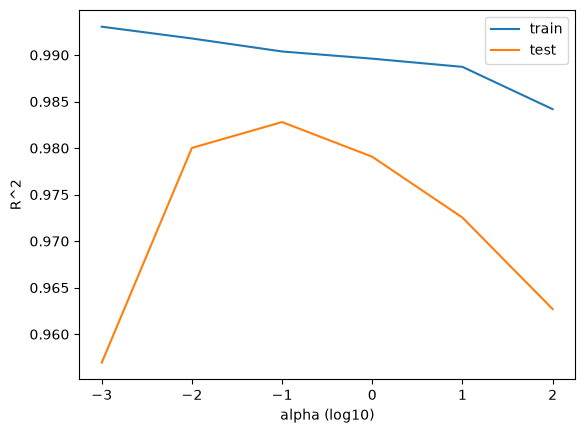

In [22]:
# 적절한 규제 강도 찾기
# 릿지 회귀의 알파는 규제 강도를 조절함 기본값이 1이며 이를 조절하여 모델의 성능 비교

import numpy as np
import matplotlib.pyplot as plt

# 점수를 저장할 리스트 생성
train_score = []
test_score = []

# 비교할 alpha 값
alpha_list = [0.001, 0.01, 0.1, 1, 10, 100]

# alpha를 변경하면서 학습
for alpha in alpha_list:

    ridge = Ridge(alpha=alpha)

    ridge.fit(train_scaled, train_target)

    train_score.append(
        ridge.score(train_scaled, train_target)
    )

    test_score.append(
        ridge.score(test_scaled, test_target)
    )

# 그래프 출력
plt.plot(np.log10(alpha_list), train_score, label='train')
plt.plot(np.log10(alpha_list), test_score, label='test')

plt.xlabel('alpha (log10)')
plt.ylabel('R^2')
plt.legend()
plt.show()

In [23]:
# 점수 표로 출력
for alpha, train, test in zip(
    alpha_list, train_score, test_score
):
    print(
        f"alpha={alpha:<7} "
        f"train={train:.6f} "
        f"test={test:.6f}"
    )

alpha=0.001   train=0.993046 test=0.956939
alpha=0.01    train=0.991781 test=0.980019
alpha=0.1     train=0.990382 test=0.982798
alpha=1       train=0.989610 test=0.979069
alpha=10      train=0.988728 test=0.972533
alpha=100     train=0.984184 test=0.962704


In [24]:
# alpha=0.1로 재학습
ridge = Ridge(alpha=0.1)

ridge.fit(train_scaled, train_target)

print(ridge.score(train_scaled, train_target))
print(ridge.score(test_scaled, test_target))

0.9903815817570367
0.9827976465386928


#### 라쏘회귀 (Lasso Regression)
라쏘도 과대적합을 줄이기 위해 규제를 적용하는 회귀 모델

![라쏘 손실 함수](./images/week06_lasso_loss_function.png)

하지만 릿지와는 규제 방식이 달라.
- 릿지 회귀: L2 규제를 사용하여 계수를 작게 만듦
- 라쏘 회귀: L1 규제를 사용하며 일부 계수를 정확히 0으로 만들 수 있음

라쏘는 계수를 0으로 만들 수 있기 때문에 불필요한 특성을 제거하는 효과도 있음

In [25]:
from sklearn.linear_model import Lasso

# 라쏘 회귀 모델 생성
lasso = Lasso()

# 모델 훈련
lasso.fit(train_scaled, train_target)

# 훈련, 테스트 점수 출력
print(lasso.score(train_scaled, train_target))
print(lasso.score(test_scaled, test_target))

0.989789897208096
0.9800593698421884


In [26]:
lasso = Lasso(alpha=10, max_iter=10000)

lasso.fit(train_scaled, train_target)

print(lasso.score(train_scaled, train_target))
print(lasso.score(test_scaled, test_target))

# 계수가 0인 특성 개수 확인
print(np.sum(lasso.coef_ == 0))

0.9887624603020236
0.9830309645308444
48


In [27]:
np.sum(lasso.coef_ == 0)

np.int64(48)

### 릿지 회귀와 라쏘 회귀 비교

릿지는 L2 규제를 사용하여 계수를 작게 만들고,
라쏘는 L1 규제를 사용하여 일부 계수를 0으로 만들 수 있다.

![Ridge와 Lasso 비교](./images/week06_ridge_lasso_comparison.png)

### 6주차 학습 흐름

농어의 길이, 높이, 두께를 이용하여 다항 특성을 생성하고,
표준화한 뒤 릿지와 라쏘 회귀를 적용하였다.

![6주차 다중 회귀 학습 흐름](./images/week06_regression_flowchart.png)